# Project 44: Air Quality Forecasting & Personalised Health Advisory System
**Course:** CSE276 — Artificial Intelligence Foundations (Session 2026–27)

## Objectives
1. Acquire and clean multi-city hourly air quality & meteorological data (CPCB / OpenAQ schema) with explicit gap handling.
2. Engineer domain-specific features: cyclical temporal encodings, boundary-layer ventilation & stagnation indices, rush-hour traffic proxies, and autoregressive pollution event history.
3. Forecast AQI across **24h, 48h, and 72h horizons** using Ridge Regression, Random Forest, Gradient Boosting (XGBoost/HistGBM), and Holt-Winters Time-Series models.
4. Benchmark every model against a **Persistence Baseline** ($\hat{y}_{t+h} = y_t$).
5. Quantify forecast uncertainty using **Quantile Regression (10th–90th percentile = 80% Prediction Interval)**.
6. Explain predictions globally and locally using **SHAP / Feature Attributions** and deliver auditable, group-specific health advisories.

In [12]:
import warnings
warnings.filterwarnings("ignore")

In [10]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

In [1]:
import os, sys
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Ensure project root is on Python path whether run from root or notebooks/
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

from src.data_pipeline import load_and_clean_data, engineer_features, create_multi_horizon_targets
from src.models import train_and_evaluate_horizon
from src.explainability import compute_feature_importance, explain_single_prediction
from src.health_advisory import generate_health_advisory

print('Environment ready. Working directory:', os.getcwd())

Environment ready. Working directory: C:\Users\RAJESHWARI SAHU\AQI-Forecasting-System


## 1. Data Loading, Cleaning & Gap Handling

In [2]:
RAW_PATH = 'data/raw/cpcb_openaq_hourly_2024_2025.csv'
CITY = 'Delhi'

df_clean = load_and_clean_data(RAW_PATH, city=CITY)
print(f'Loaded {len(df_clean):,} hourly records for {CITY} ({df_clean.timestamp.min()} to {df_clean.timestamp.max()})')
print(f'Imputed sensor gap rows handled: {df_clean["was_imputed"].sum()} ({df_clean["was_imputed"].mean()*100:.2f}%)')
df_clean.head()

Loaded 17,544 hourly records for Delhi (2024-01-01 00:00:00 to 2025-12-31 23:00:00)
Imputed sensor gap rows handled: 357 (2.03%)


,timestamp,city,PM2.5,PM10,NO2,SO2,CO,O3,Temperature_C,Humidity_pct,WindSpeed_ms,BoundaryLayer_m,Traffic_Proxy,AQI,was_imputed
0,2024-01-01 00:00:00,Delhi,287.51,565.06,47.89,20.99,1.81,31.86,19.20,56.66,0.30,343.5,0.333,500.0,0
1,2024-01-01 01:00:00,Delhi,303.06,623.76,46.81,23.47,1.91,28.18,17.28,47.95,0.85,291.5,0.310,500.0,0
2,2024-01-01 02:00:00,Delhi,334.21,644.00,48.43,26.56,2.13,17.79,20.67,55.58,0.30,234.0,0.317,500.0,0
3,2024-01-01 03:00:00,Delhi,311.72,596.18,52.72,23.90,1.70,23.63,20.84,49.33,1.51,265.9,0.346,500.0,0
4,2024-01-01 04:00:00,Delhi,294.61,477.97,56.51,22.38,1.80,9.90,15.14,56.30,0.49,357.3,0.375,460.0,0


## 2. Exploratory Data Analysis (Seasonal & Diurnal Pollution Patterns)

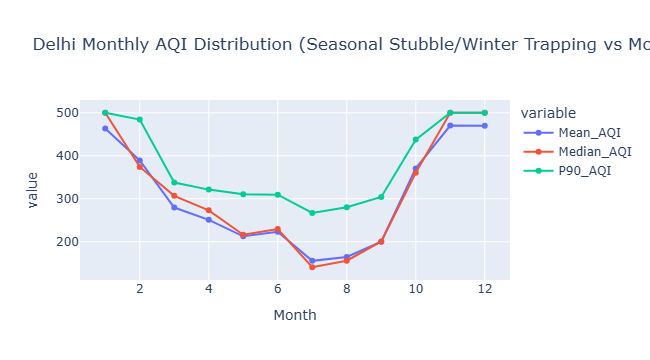

In [3]:
df_clean['month'] = df_clean['timestamp'].dt.month
df_clean['hour'] = df_clean['timestamp'].dt.hour

monthly_aqi = df_clean.groupby('month')['AQI'].agg(['mean', 'median', lambda x: np.percentile(x, 90)]).reset_index()
monthly_aqi.columns = ['Month', 'Mean_AQI', 'Median_AQI', 'P90_AQI']

fig_season = px.line(monthly_aqi, x='Month', y=['Mean_AQI', 'Median_AQI', 'P90_AQI'], markers=True,
                     title=f'{CITY} Monthly AQI Distribution (Seasonal Stubble/Winter Trapping vs Monsoon)')
fig_season.show()

## 3. Domain Feature Engineering & Multi-Horizon Target Creation

In [4]:
df_feat = engineer_features(df_clean)
df_model = create_multi_horizon_targets(df_feat, horizons=(24, 48, 72))
print('Engineered dataset shape:', df_model.shape)
df_model[['timestamp', 'AQI', 'ventilation_coeff', 'stagnation_index', 'traffic_x_stagnation', 'AQI_lag_24h', 'target_AQI_24h', 'target_AQI_72h']].head()

Engineered dataset shape: (17400, 63)


,timestamp,AQI,ventilation_coeff,stagnation_index,traffic_x_stagnation,AQI_lag_24h,target_AQI_24h,target_AQI_72h
0,2024-01-04 00:00:00,500.0,67.200,1.250000,0.301250,469.5,500.0,458.0
1,2024-01-04 01:00:00,500.0,305.298,0.568182,0.240909,500.0,500.0,500.0
2,2024-01-04 02:00:00,500.0,209.420,0.806452,0.256452,500.0,500.0,500.0
3,2024-01-04 03:00:00,500.0,128.180,0.847458,0.315254,500.0,500.0,500.0
4,2024-01-04 04:00:00,451.7,163.399,0.970874,0.240777,440.1,500.0,500.0


## 4. Model Training, Persistence Baseline Comparison & Uncertainty Calibration (24h, 48h, 72h)

In [13]:
horizon_outputs = {}
for h in [24, 48, 72]:
    metrics_df, preds_df, unc_stats, artifacts = train_and_evaluate_horizon(df_model, horizon=h, test_days=60)
    horizon_outputs[h] = (metrics_df, preds_df, unc_stats, artifacts)
    print(f'=== HORIZON: +{h} HOURS ===')
    display(metrics_df)
    print('Uncertainty Calibration:', unc_stats, '\n')

=== HORIZON: +24 HOURS ===


,MAE,RMSE,MAPE (%),R2,Skill vs Persistence (%)
Persistence Baseline,32.56,52.14,7.43,-0.257,0.00
Ridge Regression,30.65,41.74,6.78,0.194,19.95
Random Forest,28.38,39.66,6.36,0.272,23.94
Gradient Boosting (XGB/HGB),27.76,38.29,6.23,0.322,26.56
Holt-Winters Time-Series,32.81,52.87,7.43,-0.293,-1.40


Uncertainty Calibration: {'Target Coverage (%)': 80.0, 'Empirical Coverage (%)': 77.85, 'Mean Interval Width (AQI pts)': 76.64} 

=== HORIZON: +48 HOURS ===


,MAE,RMSE,MAPE (%),R2,Skill vs Persistence (%)
Persistence Baseline,36.06,56.13,8.18,-0.524,0.00
Ridge Regression,31.21,42.87,6.87,0.111,23.62
Random Forest,30.47,42.42,6.79,0.129,24.43
Gradient Boosting (XGB/HGB),29.14,40.23,6.51,0.217,28.33
Holt-Winters Time-Series,35.68,56.90,8.01,-0.567,-1.37


Uncertainty Calibration: {'Target Coverage (%)': 80.0, 'Empirical Coverage (%)': 82.29, 'Mean Interval Width (AQI pts)': 81.86} 

=== HORIZON: +72 HOURS ===


,MAE,RMSE,MAPE (%),R2,Skill vs Persistence (%)
Persistence Baseline,35.38,55.17,8.02,-0.451,0.00
Ridge Regression,29.45,40.58,6.54,0.215,26.45
Random Forest,28.79,38.81,6.45,0.282,29.65
Gradient Boosting (XGB/HGB),27.42,36.77,6.17,0.355,33.35
Holt-Winters Time-Series,35.02,55.74,7.87,-0.481,-1.03


Uncertainty Calibration: {'Target Coverage (%)': 80.0, 'Empirical Coverage (%)': 83.82, 'Mean Interval Width (AQI pts)': 77.96} 



## 5. Visualizing Forecast Uncertainty Bands (80% Prediction Interval)

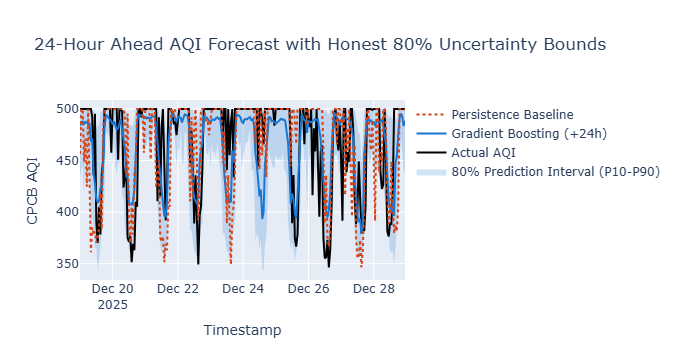

In [6]:
_, preds_24, _, artifacts_24 = horizon_outputs[24]
sample_slice = preds_24.iloc[-240:]  # Last 10 days of test set

fig = go.Figure()
fig.add_trace(go.Scatter(x=sample_slice['timestamp'], y=sample_slice['upper_80'], mode='lines', line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=sample_slice['timestamp'], y=sample_slice['lower_80'], mode='lines', line=dict(width=0),
                         fill='tonexty', fillcolor='rgba(25, 118, 210, 0.2)', name='80% Prediction Interval (P10-P90)'))
fig.add_trace(go.Scatter(x=sample_slice['timestamp'], y=sample_slice['actual'], mode='lines', line=dict(color='black', width=2), name='Actual AQI'))
fig.add_trace(go.Scatter(x=sample_slice['timestamp'], y=sample_slice['Gradient Boosting'], mode='lines', line=dict(color='#1976D2', width=2), name='Gradient Boosting (+24h)'))
fig.add_trace(go.Scatter(x=sample_slice['timestamp'], y=sample_slice['Persistence Baseline'], mode='lines', line=dict(color='#D84315', dash='dot'), name='Persistence Baseline'))
fig.update_layout(title='24-Hour Ahead AQI Forecast with Honest 80% Uncertainty Bounds', xaxis_title='Timestamp', yaxis_title='CPCB AQI')
fig.show()

## 6. Feature Importance & SHAP Explainability

,Feature,Mean_Abs_SHAP
0,AQI_roll_mean_24h,122.267379
1,AQI_roll_mean_72h,22.571435
2,doy_cos,22.458978
3,BoundaryLayer_m,18.486170
4,O3,4.515228
5,AQI_roll_std_72h,3.265690
6,doy_sin,2.169027
7,traffic_x_stagnation,1.338473
8,dew_point_proxy,1.232709
9,is_weekend,1.174136


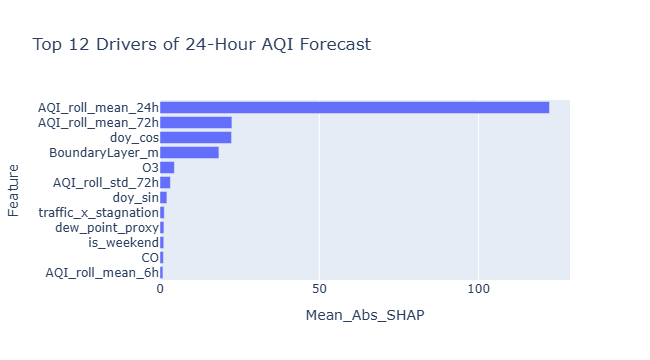

In [14]:
imp_df = compute_feature_importance(artifacts_24['rf_model'], artifacts_24['X_test'], artifacts_24['feature_cols'])
display(imp_df.head(12))

fig_imp = px.bar(imp_df.head(12).iloc[::-1], x=imp_df.columns[1], y='Feature', orientation='h',
                 title='Top 12 Drivers of 24-Hour AQI Forecast')
fig_imp.show()

## 7. Rule-Based Personalised Health Advisory Engine Demo

In [15]:
latest_row = preds_24.iloc[-1]
groups = [
    'Asthmatics & Respiratory Patients',
    'Children & School-Age Youth',
    'Elderly (65+ Years)',
    'Outdoor Workers & Athletes',
    'General Public'
]

for grp in groups:
    adv = generate_health_advisory(
        group=grp,
        forecast_median=latest_row['median_50'],
        lower_80=latest_row['lower_80'],
        upper_80=latest_row['upper_80'],
        wind_speed=1.3
    )
    print(f'*** {adv.group} | Risk: {adv.risk_level} | Band: {adv.predicted_band} (Upper: {adv.worst_case_band}) ***')
    print('Uncertainty Note:', adv.uncertainty_note)
    print('Actions:', adv.recommended_actions)
    print('Rules Fired:', adv.triggered_rules)
    print('-' * 85)

*** Asthmatics & Respiratory Patients | Risk: Critical | Band: Severe (Upper: Severe) ***
Uncertainty Note: High Forecast Confidence (80% PI: 437–500): Both central and upper bounds remain within 'Severe'.
Actions: ['Remain indoors with HEPA air purifier running on medium/high.', 'Follow written Asthma Action Plan; check peak expiratory flow twice daily.', 'Seek medical care immediately if wheezing, chest tightness, or nocturnal cough occurs.']
Rules Fired: ["RULE_BAND_MEDIAN: Central AQI 500 falls in 'Severe' (401-500).", 'RULE_CONFIDENCE_STABLE: 80% interval stays inside single CPCB category.', 'RULE_STAGNANT_AIR: Low wind speed (1.3 m/s) traps PM2.5 near ground level.', 'RULE_GROUP_ASTHMATIC: Strict threshold applied (advisory triggers at Effective AQI > 90).']
-------------------------------------------------------------------------------------
*** Children & School-Age Youth | Risk: Severe | Band: Severe (Upper: Severe) ***
Uncertainty Note: High Forecast Confidence (80% PI: 437–5

In [17]:
import os
import pickle
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from src.data_pipeline import load_and_clean_data, engineer_features, create_multi_horizon_targets
from src.models import train_and_evaluate_horizon
from src.explainability import compute_feature_importance

DATA_PATH = os.path.join("data", "raw", "cpcb_openaq_hourly_2024_2025.csv")
OUT_DIR = os.path.join("models", "web_cache")
os.makedirs(OUT_DIR, exist_ok=True)

for city in ["Delhi", "Chandigarh"]:
    print(f"Processing {city}...", flush=True)
    clean_df = load_and_clean_data(DATA_PATH, city=city)
    feat_df = engineer_features(clean_df)
    model_df = create_multi_horizon_targets(feat_df)

    model_df.tail(700).to_parquet(os.path.join(OUT_DIR, f"{city}_model_df.parquet"))

    for horizon in [24, 48, 72]:
        print(f"  Training {city} +{horizon}h...", flush=True)
        metrics_df, preds_df, unc_stats, artifacts = train_and_evaluate_horizon(
            model_df, horizon=horizon, test_days=60
        )
        imp_df = compute_feature_importance(
            artifacts["rf_model"],
            model_df[artifacts["feature_cols"]].tail(500),
            artifacts["feature_cols"],
        )

        bundle = {
            "metrics_df": metrics_df,
            "preds_df": preds_df,
            "unc_stats": unc_stats,
            "artifacts": {
                "rf_model": artifacts["rf_model"],
                "feature_cols": artifacts["feature_cols"],
            },
            "imp_df": imp_df,
        }
        with open(os.path.join(OUT_DIR, f"{city}_{horizon}h.pkl"), "wb") as f:
            pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Done! All web cache files saved in models/web_cache/")

Processing Delhi...
  Training Delhi +24h...
  Training Delhi +48h...
  Training Delhi +72h...
Processing Chandigarh...
  Training Chandigarh +24h...
  Training Chandigarh +48h...
  Training Chandigarh +72h...
Done! All web cache files saved in models/web_cache/
